# 8 · Variantes du DE sur GPU

Sur la même organisation que la version 2, nous avons comparé six variantes du DE : DE/rand/1 avec quatre
valeurs de CR, current-to-best/1, et jDE, où chaque individu adapte ses propres F et CR. Le code est dans
`src/cuda/de_cuda_variantes.cu` ; la version 2 elle-même n'est pas modifiée.

| Variante | Mutation | F | CR |
|---|---|---|---|
| **rand1 CR=0,3** (référence = v2) | v = x_r1 + F (x_r2 − x_r3) | 0,5 | 0,3 |
| rand1 CR=0,1 / 0,5 / 0,9 | idem | 0,5 | 0,1 / 0,5 / 0,9 |
| **ctb1** (current-to-best/1) | v = x_i + F (x_best − x_i) + F (x_r1 − x_r2) | 0,5 | 0,3 |
| **jDE** (Brest et al., 2006) | v = x_r1 + F_i (x_r2 − x_r3) | F_i auto-adapté | CR_i auto-adapté |

- **ctb1** : x_best est le meilleur individu de la génération courante, trouvé sur GPU par `k_argmin` **avant** le kernel MCER (un lancement de plus par génération). La recherche est plus « gloutonne » : elle converge plus vite mais peut se bloquer dans un minimum local.
- **jDE** : chaque individu porte ses propres F_i et CR_i (départ : 0,5 et 0,9). À chaque génération, avec une probabilité 0,1, F' est retiré dans [0,1 ; 1] et, avec une probabilité 0,1, CR' est retiré dans [0 ; 1]. L'essai est construit avec (F', CR') ; s'il remplace x_i, les nouveaux paramètres sont gardés. F et CR sont donc eux aussi en double tampon sur le GPU.

Nous vérifions d'abord que la variante rand/1 avec CR = 0,3 redonne exactement les résultats de la v2.
Nous lançons ensuite les 240 runs (D = 50, N = 100, 10 graines, 4 fonctions, 6 variantes), puis nous
comparons la qualité des variantes (Kruskal-Wallis et classement par rang moyen), les valeurs de F et CR
apprises par jDE, les temps et les courbes de convergence.

In [1]:
# Récupérer le projet.
# Si DE_CUDA.zip a été déposé dans Colab (icône dossier à gauche → Importer), on utilise ce dossier ;
# sinon on copie le dépôt public GitHub (aucun compte nécessaire).
import os
if os.path.exists("/content/DE_CUDA.zip") and not os.path.exists("/content/DE_CUDA/src"):
    !unzip -q -o /content/DE_CUDA.zip -d /content
if not os.path.exists("/content/DE_CUDA/src"):
    !git clone -q https://github.com/amenacer/DE_CUDA.git /content/DE_CUDA
%cd /content/DE_CUDA
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv

/content/DE_CUDA
name, driver_version, memory.total [MiB]
Tesla T4, 580.82.07, 15360 MiB


In [2]:
import subprocess, re, statistics as st, os, json
ROOT = "/content/DE_CUDA"
RAPPORT = []                       # tout ce qui est affiche est aussi garde pour le rapport
def note(s=""):
    print(s); RAPPORT.append(str(s))

def run(args, cwd=ROOT, ok_codes=(0,)):
    p = subprocess.run(args, cwd=cwd, capture_output=True, text=True)
    if p.returncode not in ok_codes:
        print(p.stdout); print(p.stderr)
        raise RuntimeError(f"{args[0]} a renvoye {p.returncode}")
    return p

def compile_cuda(src, out):
    p = run(["nvcc", "-O3", "-arch=sm_75", "-Xcompiler", "-Wall", "-Xcompiler", "-Wextra",
             "-o", out, src], cwd=f"{ROOT}/src/cuda")
    warn = (p.stdout + p.stderr).strip()
    note(f"{src} : " + ("compilation SANS aucun warning" if not warn else "WARNINGS :\n" + warn))

KV = re.compile(r"(\w+)=(\S+)")
def lance(prog, f, D, N, seed, csv=None, extra=()):
    """Lance un run et renvoie le dictionnaire de sa derniere ligne (best_error, time_s, ...)."""
    args = [prog, f, str(D), str(N), str(seed)] + ([csv] if csv else []) + list(extra)
    out = run(args).stdout.strip().splitlines()[-1]
    d = dict(KV.findall(out))
    for k in ("best_error", "time_s"):
        d[k] = float(d[k])
    return d

def mann_whitney(a, b):
    """p-valeur du test de Mann-Whitney bilateral ; 1.0 si les deux series sont identiques et constantes."""
    from scipy.stats import mannwhitneyu
    if len(set(a) | set(b)) == 1:
        return 1.0
    return float(mannwhitneyu(a, b, alternative="two-sided").pvalue)

def tableau_md(lignes, entetes):
    s = "| " + " | ".join(entetes) + " |\n|" + "---|" * len(entetes) + "\n"
    for l in lignes:
        s += "| " + " | ".join(str(x) for x in l) + " |\n"
    return s
print("outils prets")

outils prets


## 1. Compiler la v2 et les variantes

In [3]:
compile_cuda("de_cuda_v2.cu", "de_cuda_v2")
compile_cuda("de_cuda_variantes.cu", "de_cuda_variantes")
V2  = f"{ROOT}/src/cuda/de_cuda_v2"
VAR = f"{ROOT}/src/cuda/de_cuda_variantes"
VARIANTES = [   # (nom affiche, options de la ligne de commande)
    ("rand1 CR=0,1",  ["--strategie", "rand1", "--CR", "0.1"]),
    ("rand1 CR=0,3",  ["--strategie", "rand1", "--CR", "0.3"]),   # = v2, reference
    ("rand1 CR=0,5",  ["--strategie", "rand1", "--CR", "0.5"]),
    ("rand1 CR=0,9",  ["--strategie", "rand1", "--CR", "0.9"]),
    ("ctb1 CR=0,3",   ["--strategie", "ctb1",  "--CR", "0.3"]),
    ("jDE",           ["--strategie", "jde"]),
]
REF = "rand1 CR=0,3"
FONCTIONS = ["sphere", "rosenbrock", "griewank", "rastrigin"]
D, N, SEEDS = 50, 100, range(1, 11)
print(run([VAR, "sphere", "10", "50", "1", "--strategie", "jde"]).stdout)

de_cuda_v2.cu : compilation SANS aucun warning
de_cuda_variantes.cu : compilation SANS aucun warning
algo=gpu_jde func=sphere D=10 N=50 seed=1 best_error=0.000000000e+00 FE=100000 maxFE=100000 time_s=0.032197 threads=32 F_moyen=0.5931 CR_moyen=0.5155 sante=OK



## 2. Contrôle : rand/1 avec CR = 0,3 = v2 au bit près

Les deux programmes partagent le même code de tirage aléatoire ; avec la même graine ils doivent donner exactement la même erreur finale. C'est la preuve que le nouveau code ne change rien à la v2 quand on choisit ses paramètres.

In [4]:
lignes, tout_ok = [], True
for f in FONCTIONS:
    for seed in (1, 2, 3):
        a = lance(V2, f, D, N, seed)["best_error"]
        b = lance(VAR, f, D, N, seed, extra=["--strategie", "rand1", "--CR", "0.3"])["best_error"]
        tout_ok &= (a == b)
        lignes.append([f, seed, f"{a:.9e}", f"{b:.9e}", "identique" if a == b else "DIFFERENT"])
note(f"Controle v2 contre variantes (rand1, F = 0,5, CR = 0,3), D = {D}, N = {N}")
note(tableau_md(lignes, ["fonction", "graine", "v2", "variantes rand1", "verdict"]))
note("=> " + ("OK : resultats identiques au bit pres" if tout_ok else "ECHEC : les resultats different"))
assert tout_ok

Controle v2 contre variantes (rand1, F = 0,5, CR = 0,3), D = 50, N = 100
| fonction | graine | v2 | variantes rand1 | verdict |
|---|---|---|---|---|
| sphere | 1 | 0.000000000e+00 | 0.000000000e+00 | identique |
| sphere | 2 | 0.000000000e+00 | 0.000000000e+00 | identique |
| sphere | 3 | 0.000000000e+00 | 0.000000000e+00 | identique |
| rosenbrock | 1 | 4.113724274e+01 | 4.113724274e+01 | identique |
| rosenbrock | 2 | 4.041335155e+01 | 4.041335155e+01 | identique |
| rosenbrock | 3 | 4.139833952e+01 | 4.139833952e+01 | identique |
| griewank | 1 | 0.000000000e+00 | 0.000000000e+00 | identique |
| griewank | 2 | 0.000000000e+00 | 0.000000000e+00 | identique |
| griewank | 3 | 0.000000000e+00 | 0.000000000e+00 | identique |
| rastrigin | 1 | 1.536470311e+02 | 1.536470311e+02 | identique |
| rastrigin | 2 | 1.601138035e+02 | 1.601138035e+02 | identique |
| rastrigin | 3 | 1.631731634e+02 | 1.631731634e+02 | identique |

=> OK : resultats identiques au bit pres


## 3. Les 240 runs : 4 fonctions × 6 variantes × 10 graines

In [5]:
os.makedirs(f"{ROOT}/results", exist_ok=True)
CSV_VAR = f"{ROOT}/results/variantes_gpu_D50_N100.csv"
if os.path.exists(CSV_VAR): os.remove(CSV_VAR)
ERR, TPS, JDE_PARAM = {}, {}, {}
for f in FONCTIONS:
    for nom, opts in VARIANTES:
        ERR[(f, nom)], TPS[(f, nom)] = [], []
        for seed in SEEDS:
            d = lance(VAR, f, D, N, seed, CSV_VAR, extra=opts)
            assert d["sante"] == "OK", d
            ERR[(f, nom)].append(d["best_error"]); TPS[(f, nom)].append(d["time_s"])
            if nom == "jDE":
                JDE_PARAM.setdefault(f, []).append((float(d["F_moyen"]), float(d["CR_moyen"])))
    print(f, "fait")
print("lignes CSV :", sum(1 for _ in open(CSV_VAR)) - 1)

sphere fait
rosenbrock fait
griewank fait
rastrigin fait
lignes CSV : 240


## 4. Qualité, Kruskal-Wallis et classement

- **Kruskal-Wallis** : les 6 variantes donnent-elles la même distribution d'erreurs ? (p < 0,05 → au moins une variante diffère.)
- **Rang moyen** : on classe ensemble les 60 erreurs d'une fonction (rang 1 = la plus petite) et on fait la moyenne des rangs de chaque variante. Rang moyen faible = meilleure variante. Les ex æquo reçoivent le rang moyen.
- **Mann-Whitney contre la référence**, p-valeurs corrigées par **Holm** (5 comparaisons par fonction).

In [6]:
from scipy.stats import kruskal, rankdata

def holm(ps):
    """p-valeurs ajustees de Holm (dans l'ordre d'entree)."""
    m = len(ps); ordre = sorted(range(m), key=lambda k: ps[k])
    adj, courant = [0.0] * m, 0.0
    for rang, k in enumerate(ordre):
        courant = max(courant, min(1.0, (m - rang) * ps[k]))
        adj[k] = courant
    return adj

noms = [n for n, _ in VARIANTES]
RANG = {}
for f in FONCTIONS:
    series = [ERR[(f, n)] for n in noms]
    valeurs = [v for s in series for v in s]
    if len(set(valeurs)) == 1:
        p_kw, h = 1.0, 0.0
    else:
        h, p_kw = kruskal(*series)
    rangs = rankdata(valeurs)
    for k, n in enumerate(noms):
        RANG[(f, n)] = float(st.mean(rangs[k * len(SEEDS):(k + 1) * len(SEEDS)]))
    autres = [n for n in noms if n != REF]
    p_mw = holm([mann_whitney(ERR[(f, REF)], ERR[(f, n)]) for n in autres])
    p_mw = dict(zip(autres, p_mw))
    classement = sorted(noms, key=lambda n: RANG[(f, n)])
    lignes = []
    for n in classement:
        e = ERR[(f, n)]
        lignes.append([classement.index(n) + 1, n, f"{st.mean(e):.3e} ± {st.pstdev(e):.2e}", f"{st.median(e):.3e}",
                       f"{RANG[(f, n)]:.1f}",
                       "reference" if n == REF else f"{p_mw[n]:.3g}" + (" *" if p_mw[n] < 0.05 else "")])
    note(f"{f} (D = {D}, N = {N}, 10 runs) -- Kruskal-Wallis : H = {h:.2f}, p = {p_kw:.3g}"
         + (" => difference significative entre variantes" if p_kw < 0.05 else " => pas de difference detectee"))
    note(tableau_md(lignes, ["rang", "variante", "moyenne ± ET", "mediane", "rang moyen", "p Holm vs reference"]))
lignes = [[n] + [f"{RANG[(f, n)]:.1f}" for f in FONCTIONS] + [f"{st.mean(RANG[(f, n)] for f in FONCTIONS):.2f}"]
          for n in sorted(noms, key=lambda n: st.mean(RANG[(f, n)] for f in FONCTIONS))]
note("Classement global (rang moyen par fonction, puis moyenne des 4 fonctions ; plus petit = meilleur)")
note(tableau_md(lignes, ["variante"] + FONCTIONS + ["moyenne"]))
note("* : p Holm < 0,05. Les ecarts-types sont des ecarts-types de population (statistics.pstdev).")

sphere (D = 50, N = 100, 10 runs) -- Kruskal-Wallis : H = 36.97, p = 6.06e-07 => difference significative entre variantes
| rang | variante | moyenne ± ET | mediane | rang moyen | p Holm vs reference |
|---|---|---|---|---|---|
| 1 | rand1 CR=0,1 | 0.000e+00 ± 0.00e+00 | 0.000e+00 | 23.5 | 1 |
| 2 | rand1 CR=0,3 | 0.000e+00 ± 0.00e+00 | 0.000e+00 | 23.5 | reference |
| 3 | jDE | 0.000e+00 ± 0.00e+00 | 0.000e+00 | 23.5 | 1 |
| 4 | rand1 CR=0,5 | 5.167e-30 ± 1.37e-29 | 0.000e+00 | 28.3 | 0.504 |
| 5 | rand1 CR=0,9 | 6.058e-29 ± 9.25e-29 | 0.000e+00 | 32.2 | 0.307 |
| 6 | ctb1 CR=0,3 | 2.386e-28 ± 1.18e-28 | 2.019e-28 | 52.0 | 0.00101 * |

rosenbrock (D = 50, N = 100, 10 runs) -- Kruskal-Wallis : H = 43.49, p = 2.95e-08 => difference significative entre variantes
| rang | variante | moyenne ± ET | mediane | rang moyen | p Holm vs reference |
|---|---|---|---|---|---|
| 1 | rand1 CR=0,9 | 2.772e+01 ± 1.62e+01 | 2.220e+01 | 12.9 | 0.00565 * |
| 2 | jDE | 3.295e+01 ± 2.05e+01 | 2.336e+01 | 1

## 5. Ce que jDE a appris

Moyenne, sur la population finale, des F_i et CR_i (puis moyenne sur les 10 runs). Départ : F = 0,5, CR = 0,9.

In [7]:
lignes = [[f, f"{st.mean(p[0] for p in JDE_PARAM[f]):.3f}", f"{st.mean(p[1] for p in JDE_PARAM[f]):.3f}"] for f in FONCTIONS]
note("jDE : parametres moyens en fin de run (10 runs)")
note(tableau_md(lignes, ["fonction", "F moyen", "CR moyen"]))

jDE : parametres moyens en fin de run (10 runs)
| fonction | F moyen | CR moyen |
|---|---|---|
| sphere | 0.557 | 0.512 |
| rosenbrock | 0.373 | 0.545 |
| griewank | 0.378 | 0.309 |
| rastrigin | 0.365 | 0.320 |



## 6. Temps par variante

ctb1 lance un kernel de plus par génération (argmin) ; jDE lit et écrit F et CR en plus.

In [8]:
lignes = [[n] + [f"{st.mean(TPS[(f, n)]):.4f}" for f in FONCTIONS] for n in noms]
note(f"Temps moyen (s) par run, D = {D}, N = {N}, 10 runs")
note(tableau_md(lignes, ["variante"] + FONCTIONS))

Temps moyen (s) par run, D = 50, N = 100, 10 runs
| variante | sphere | rosenbrock | griewank | rastrigin |
|---|---|---|---|---|
| rand1 CR=0,1 | 0.0490 | 0.0520 | 0.0679 | 0.0577 |
| rand1 CR=0,3 | 0.0493 | 0.0525 | 0.0684 | 0.0583 |
| rand1 CR=0,5 | 0.0495 | 0.0527 | 0.0699 | 0.0586 |
| rand1 CR=0,9 | 0.0489 | 0.0519 | 0.0679 | 0.0577 |
| ctb1 CR=0,3 | 0.0697 | 0.0718 | 0.0875 | 0.0775 |
| jDE | 0.0576 | 0.0624 | 0.0772 | 0.0671 |



## 7. Courbes de convergence (graine 1)

`--trace` affiche la meilleure erreur à chaque génération. Le mode trace ajoute un argmin et une copie par génération : ces runs ne servent qu'aux courbes, pas aux temps.

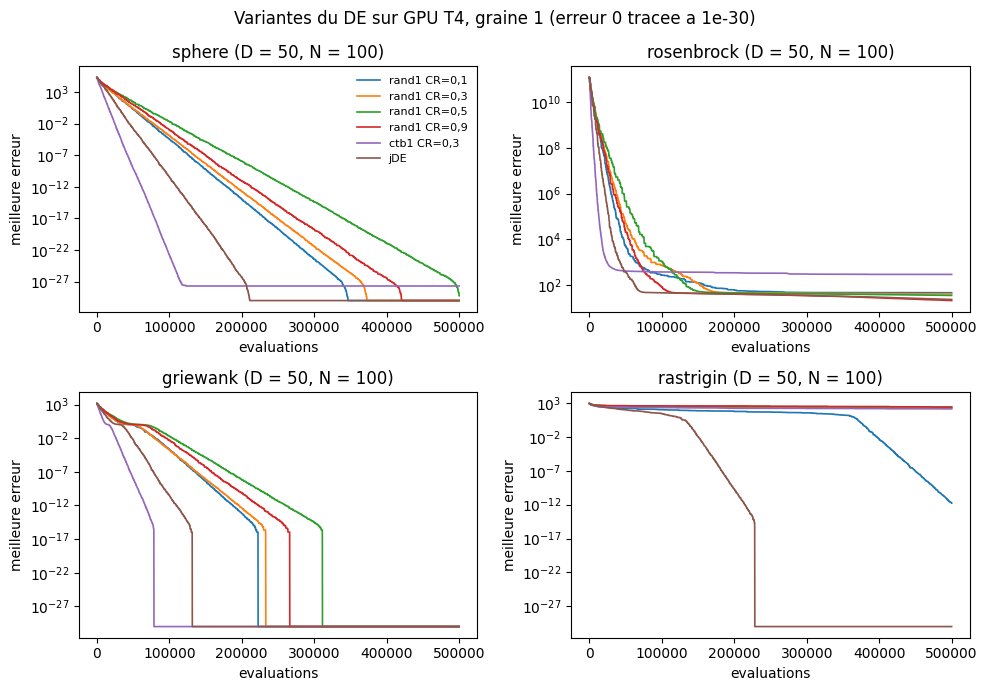

In [9]:
import matplotlib.pyplot as plt
os.makedirs(f"{ROOT}/figures", exist_ok=True)
TR = re.compile(r"TRACE gen=\d+ FE=(\d+) best_error=(\S+)")
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axs.flat, FONCTIONS):
    for nom, opts in VARIANTES:
        out = run([VAR, f, str(D), str(N), "1", "--trace"] + opts).stdout
        pts = [(int(a), float(b)) for a, b in TR.findall(out)]
        ax.plot([p[0] for p in pts], [max(p[1], 1e-30) for p in pts], label=nom, lw=1.2)
    ax.set_yscale("log"); ax.set_title(f"{f} (D = {D}, N = {N})")
    ax.set_xlabel("evaluations"); ax.set_ylabel("meilleure erreur")
axs[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Variantes du DE sur GPU T4, graine 1 (erreur 0 tracee a 1e-30)"); fig.tight_layout()
fig.savefig(f"{ROOT}/figures/convergence_variantes_D50.png", dpi=200); plt.show()

## 8. Rapport

La dernière cellule enregistre les résultats ci-dessus dans `results/etape7_variantes_gpu.md`.

In [10]:
os.makedirs(f"{ROOT}/results", exist_ok=True)
with open(f"{ROOT}/results/etape7_variantes_gpu.md", "w") as fp:
    fp.write("# Étape 7 — Variantes du DE sur GPU\n\n")
    fp.write("GPU : " + run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"]).stdout.strip() + "\n\n")
    fp.write("```\n" + "\n".join(RAPPORT) + "\n```\n")